# Домашнее задание "Корреляционный и регрессионный анализ"

Инструкции:
- Скачайте файл `practical_module_dataset.csv` и заполните ячейки с заданиями кодом и выводами.
- В каждой задаче требуется: короткая формулировка метода, код и расчёты, численные результаты (коэффициенты, статистики, p-value, CI, R^2) и краткий вывод (1-2 фразы).
- Разрешённые библиотеки: `numpy`, `pandas`, `scipy`, `statsmodels`, `scikit-learn`, `matplotlib`.
- Для воспроизводимости задан `np.random.seed` - не меняйте его.

Формат сдачи: .ipynb с заполненными ячейками, кодом и выводами.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

np.random.seed(28)

In [2]:
df = pd.read_csv('practical_module_dataset.csv')
print(df.shape)
df.head()

(30, 8)


,id,age,height_cm,weight_kg,iq,tv_hours,study_hours,score
0,1,24,155.2,51.37,91,11,11.9,76.5
1,2,37,184.9,76.49,90,15,4.0,65.4
2,3,32,169.8,64.24,98,6,10.6,78.2
3,4,28,173.6,68.22,88,9,9.2,75.6
4,5,25,174.2,73.80,102,8,8.0,75.1


### Задание 1. Первичный анализ данных (EDA)

- Посмотрите на основные статистические показатели для **всех** переменных.
- Проверьте типы данных и наличие пропусков.
- Постройте гистограммы числовых признаков.
- Запишите наблюдения в текстовой ячейке.

**Метод:** Типы, пропуски, описательные статистики и гистограммы; id не используем как содержательный признак.

In [3]:
# Проверяем типы признаков перед анализом.
df.dtypes

id               int64
age              int64
height_cm      float64
weight_kg      float64
iq               int64
tv_hours         int64
study_hours    float64
score          float64
dtype: object

In [4]:
# True означает, что в столбце нет пропусков.
df.isna().sum() == 0

id             True
age            True
height_cm      True
weight_kg      True
iq             True
tv_hours       True
study_hours    True
score          True
dtype: bool

In [5]:
# Смотрим основные статистики всех переменных.
df.describe().round(2)

,id,age,height_cm,weight_kg,iq,tv_hours,study_hours,score
count,30.00,30.00,30.00,30.00,30.00,30.00,30.00,30.00
mean,15.50,29.40,169.15,62.73,100.43,12.27,7.64,73.40
std,8.80,6.67,9.58,9.20,12.12,3.83,3.28,8.25
min,1.00,18.00,148.20,44.75,82.00,6.00,2.70,58.90
25%,8.25,24.25,163.25,56.62,91.00,9.00,4.98,67.80
50%,15.50,29.00,169.75,63.68,97.00,12.00,7.65,74.30
75%,22.75,35.50,174.10,68.60,109.75,14.00,9.45,78.73
max,30.00,39.00,185.80,81.13,132.00,22.00,14.40,91.50


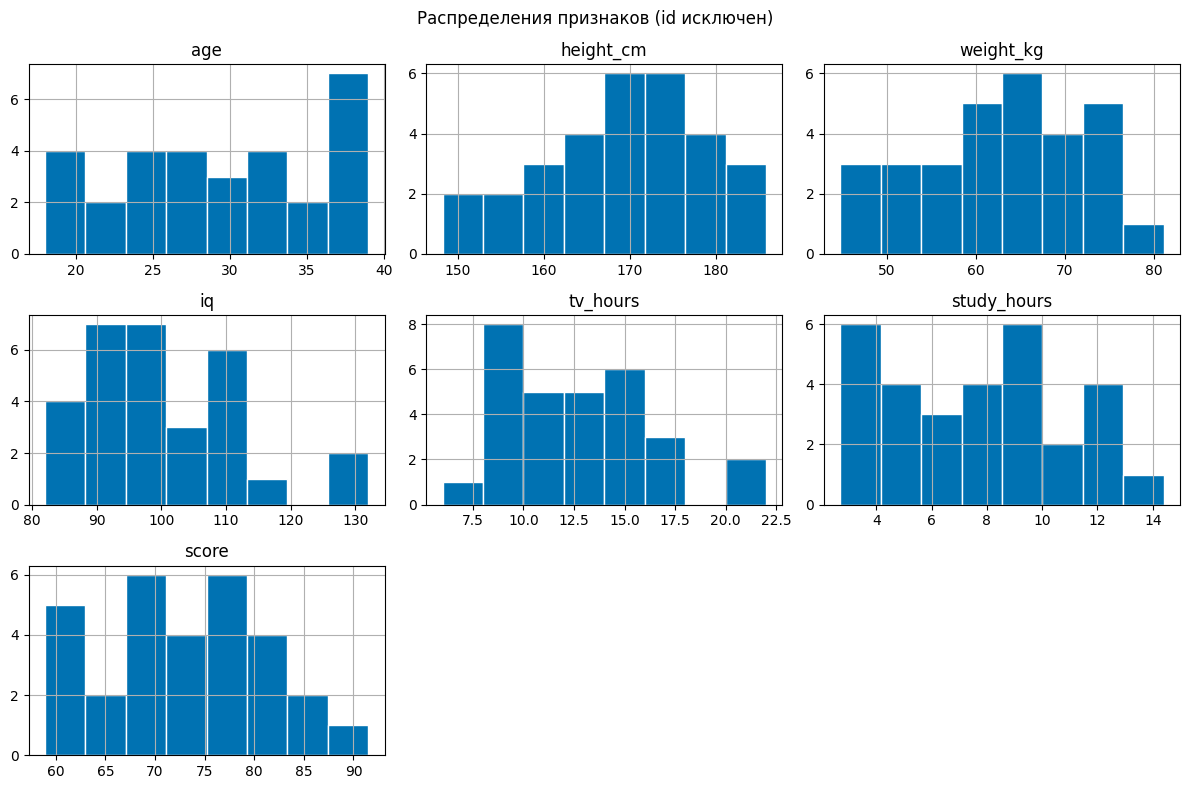

In [6]:
# Сравниваем распределения признаков; id — номер записи, а не характеристика человека.
features = df.drop(columns="id")
features.hist(bins=8, figsize=(12, 8), color="#0072B2", edgecolor="white")
plt.suptitle("Распределения признаков (id исключен)")
plt.tight_layout()
plt.show()

**Вывод:**

**age**

среднее 29,40 года, стандартное отклонение 6,67 года, диапазон от 18 до 39 лет
на гистограмме больше наблюдений в диапазоне 36–39 лет
явной асимметрии не видно
повышенная частота возрастов 36–39 лет не является выбросом

**height_cm**

среднее 169,15 см, стандартное отклонение 9,58 см
половина наблюдений находится между 163,25 и 174,10 см
основная масса наблюдений сосредоточена около центра, левый хвост немного длиннее

**weight_kg**

среднее 62,73 кг, стандартное отклонение 9,20 кг
значения от 44,75 до 81,13 кг, половина наблюдений находится между 56,62 и 68,60 кг
распределение визуально близко к симметричному

**iq**

среднее 100,43 выше медианы 97, стандартное отклонение 12,12
половина наблюдений находится между 91 и 109,75, максимальное значение — 132
заметен более длинный правый хвост
высокие значения около 127–132 выделяются, но по гистограмме нельзя однозначно назвать их выбросами

**tv_hours**

среднее 12,27 часа, стандартное отклонение 3,83 часа
половина наблюдений находится между 9 и 14 часами
правый хвост длиннее левого
два значения по 22 отделены от основной массы наблюдений и могут рассматриваться как потенциальные выбросы

**study_hours**

среднее 7,64 часа почти совпадает с медианой 7,65 часа, стандартное отклонение 3,28 часа
значения находятся в диапазоне от 2,70 до 14,40 часа
выраженной асимметрии не видно, частоты по интервалам неровные.

**score**

среднее 73,40 балла, медиана 74,30, стандартное отклонение 8,25 балла
значения от 58,90 до 91,50 балла, половина наблюдений находится между 67,80 и 78,73 балла
выраженной асимметрии не видно, частоты по интервалам неровные



### Задание 2. Связь height_cm и weight_kg

- Постройте scatter plot по признакам `height_cm` и `weight_kg`.
- Посчитайте коэффициент Пирсона и p-value.
- Интерпретируйте силу, направление и значимость связи в выводе.

**Метод:** Корреляция Пирсона и диаграмма рассеяния, двусторонняя проверка при α = 0,05.

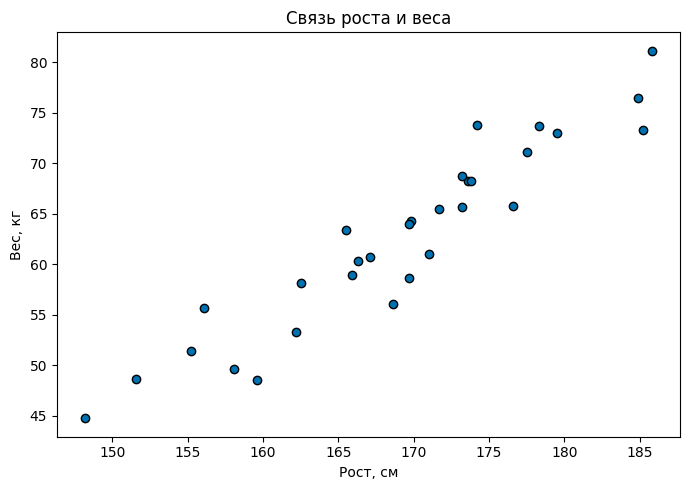

In [7]:
# Оцениваем линейную связь роста и веса; H0: ρ = 0, H1: ρ <> 0, α = 0,05.
plt.figure(figsize=(7, 5))
plt.scatter(df["height_cm"], df["weight_kg"], color="#0072B2", edgecolors="black")
plt.xlabel("Рост, см")
plt.ylabel("Вес, кг")
plt.title("Связь роста и веса")
plt.tight_layout()
plt.show()

In [8]:
r, p_pearson = stats.pearsonr(df["height_cm"], df["weight_kg"])
print(f"Коэффициент Пирсона: {r:.4f}; p-value: {p_pearson:.6g}")

Коэффициент Пирсона: 0.9435; p-value: 5.79897e-15


**Вывод:** Так как коэффициент Пирсона r = 0,9435 то делаем вывод, что между ростом и весом есть сильная положительная линейная связь: большему росту обычно соответствует больший вес.
Так как p-value меньше 0,05, связь статистически значима: отвергаем гипотезу о нулевой линейной корреляции.

### Задание 3. Связь tv_hours и iq

- Посчитайте ранговый коэффициент Спирмена между `tv_hours` и `iq` и p-value.
- Оцените, есть ли монотонная связь в выводе.

**Метод:** Ранговая корреляция Спирмена, двусторонняя проверка при α = 0,05.

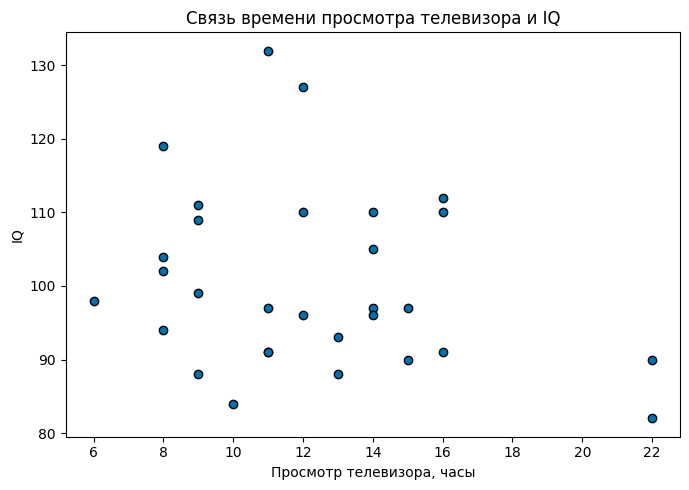

In [9]:
# Смотрим, как IQ связан с количеством часов просмотра телевизора.
plt.figure(figsize=(7, 5))
plt.scatter(df["tv_hours"], df["iq"], color="#0072B2", edgecolors="black")
plt.xlabel("Просмотр телевизора, часы")
plt.ylabel("IQ")
plt.title("Связь времени просмотра телевизора и IQ")
plt.tight_layout()
plt.show()

In [10]:
# Проверяем монотонную связь времени просмотра телевизора и IQ с помощью коэффициента Спирмена.
# H0: ρ_s = 0, H1: ρ_s <> 0.
r_s, p_spearman = stats.spearmanr(df["tv_hours"], df["iq"])
print(f"Коэффициент Спирмена: {r_s:.4f}; p-value: {p_spearman:.6f}")

Коэффициент Спирмена: -0.2108; p-value: 0.263541


**Вывод:**  

Коэффициент Спирмена r_s = −0,2108 показывает слабую отрицательную связь в выборке,  
но p-value = 0,263541 больше 0,05. Поэтому нет оснований отвергать гипотезу об отсутствии  
ранговой корреляции: статистически значимая монотонная связь между tv_hours и iq не обнаружена.

### Задание 4. Простая линейная регрессия weight_kg ~ height_cm

- Постройте регрессию, найдите intercept и slope, 95% доверительный интервал для наклона.
- Интерпретируйте результат в выводе.

**Метод:** Линейная регрессия со свободным членом, МНК и 95% доверительный интервал наклона.

In [11]:
# Оцениваем, как средний вес связан с ростом, методом наименьших квадратов.
X_height = sm.add_constant(df[["height_cm"]])
weight_model = sm.OLS(df["weight_kg"], X_height).fit()
slope_ci = weight_model.conf_int(alpha=0.05).loc["height_cm"]

print(f"w0 — свободный член: {weight_model.params['const']:.4f} кг")
print(f"w1 — наклон: {weight_model.params['height_cm']:.4f} кг/см")
print(f"95% доверительный интервал наклона w1: [{slope_ci.iloc[0]:.4f}, {slope_ci.iloc[1]:.4f}] кг/см")

w0 — свободный член: -90.4962 кг
w1 — наклон: 0.9059 кг/см
95% доверительный интервал наклона w1: [0.7827, 1.0290] кг/см


**Вывод:**

Получили модель weight_kg = w0 + w1 × height_cm, где w0 = −90,4962 кг, w1 = 0,9059 кг/см:  
разнице роста в 1 см соответствует разница среднего прогнозируемого веса примерно в 0,91 кг.  
95% доверительный интервал наклона w1 [0,7827; 1,0290] кг/см целиком выше нуля,  
поэтому связь положительная и статистически значимая;  
свободный член w0 не интерпретируем как реальный вес при нулевом росте, 
поскольку нулевой рост невозможен.

### Задание 5. Прогноз и предсказательный интервал

- Для `height_cm = 175` вычислите точечный прогноз веса и 95% предсказательный интервал для нового наблюдения.

**Метод:** Прогноз простой регрессии и 95% интервал для нового наблюдения, а не для среднего веса.

In [12]:
# Прогнозируем вес человека ростом 175 см и оцениваем возможный разброс его веса.
new_height = pd.DataFrame({"const": [1.0], "height_cm": [175.0]})
prediction = weight_model.get_prediction(new_height).summary_frame(alpha=0.05)

print(f"Прогноз веса при росте 175 см: {prediction['mean'].iloc[0]:.2f} кг")
print(
    f"95% предсказательный интервал: "
    f"[{prediction['obs_ci_lower'].iloc[0]:.2f}, "
    f"{prediction['obs_ci_upper'].iloc[0]:.2f}] кг"
)

Прогноз веса при росте 175 см: 68.03 кг
95% предсказательный интервал: [61.53, 74.53] кг


**Вывод:**

Для человека ростом 175 см модель прогнозирует вес 68,03 кг.  
95% предсказательный интервал составляет [61,53; 74,53] кг:  
он учитывает, что люди одного роста могут иметь разный вес.

### Задание 6. Множественная регрессия

- Постройте модель score `~ study_hours + iq + tv_hours + age`.
- Выведите R^2 и оцените значимость предикторов по p-value.
- Дополнительно проверьте мультиколлинеарность через VIF.
- Запшите наблюдения в выводе.

**Метод:** Множественная линейная регрессия, p-value при α = 0,05, R² и VIF предикторов.

In [13]:
# Оцениваем связь каждого признака с баллом при фиксированных остальных признаках.
predictors = ["study_hours", "iq", "tv_hours", "age"]
X_score = sm.add_constant(df[predictors])
score_model = sm.OLS(df["score"], X_score).fit()

coefficients = pd.DataFrame({
    "Коэффициент": score_model.params,
    "p-value": score_model.pvalues,
})
coefficients

,Коэффициент,p-value
const,45.658396,4.979884e-07
study_hours,2.097834,6.056409e-11
iq,0.147930,1.005923e-02
tv_hours,-0.144698,3.701764e-01
age,-0.046532,6.141056e-01


In [14]:
# Оцениваем, какую долю разброса баллов описывает модель.
print(f"R²: {score_model.rsquared:.4f}")

R²: 0.8741

In [15]:
# Проверяем, не мешает ли связь между признаками оценивать их отдельные коэффициенты.
vif = pd.Series(
    [
        variance_inflation_factor(X_score.to_numpy(), i)
        for i in range(1, X_score.shape[1])
    ],
    index=predictors,
    name="VIF",
)
vif.round(4)

study_hours    1.1737
iq             1.2077
tv_hours       1.0759
age            1.0776
Name: VIF, dtype: float64

**Вывод:**

- Модель описывает 87,41% разброса баллов (R² = 0,8741).
- При учете остальных признаков часы учебы и IQ связаны с баллом статистически значимо,  
  так как оба p-value меньше уровня значимости 0,05:  
  study_hours — коэффициент 2,0978, p-value ≈ 6,06 × 10⁻¹¹;  
  iq — коэффициент 0,1479, p-value = 0,0101.
- Для времени просмотра телевизора и возраста значимая связь не обнаружена:  
  p-value для tv_hours = 0,3702, для age = 0,6141 — оба больше 0,05.
- VIF находится в диапазоне 1,08–1,21: сильной линейной зависимости между признаками не выявлено.

### Задание 7. Ошибка модели

- Оцените типичную ошибку предсказаний модели из задания 6: вычислите RMSE (корень из средней квадратичной ошибки) на всей выборке и сравните её с разбросом целевой переменной (стандартным отклонением score).
- Насколько модель уменьшает типичную ошибку?

**Метод:** RMSE на всей исходной выборке и сравнение с разбросом score и прогнозом средним.

In [16]:
# Сравниваем ошибку модели с разбросом баллов на той же выборке.
rmse = np.sqrt(np.mean(score_model.resid ** 2))
score_std = df["score"].std(ddof=1)
baseline_rmse = np.sqrt(np.mean((df["score"] - df["score"].mean()) ** 2))
rmse_reduction = (1 - rmse / baseline_rmse) * 100

print(f"RMSE модели: {rmse:.4f} балла")
print(f"Стандартное отклонение score: {score_std:.4f} балла")
print(f"RMSE прогноза средним: {baseline_rmse:.4f} балла")
print(f"Снижение RMSE относительно прогноза средним: {rmse_reduction:.2f}%")

RMSE модели: 2.8797 балла
Стандартное отклонение score: 8.2537 балла
RMSE прогноза средним: 8.1150 балла
Снижение RMSE относительно прогноза средним: 64.51%


**Вывод:**

RMSE модели составляет 2,88 балла при стандартном отклонении score 8,25 балла:  
по сравнению с прогнозом одним средним ошибка снизилась с 8,12 до 2,88 балла, то есть на 64,51%.  
На этой выборке модель прогнозирует баллы заметно лучше, чем прогноз одним средним,  
поэтому учитывать признаки полезно.  
Чтобы решить, подходит ли модель для прогнозов новых результатов,  
нужно проверить её на новых данных и определить, какая ошибка допустима.

### Задание 8. Градиентный спуск

- Реализуйте градиентный спуск для простой регрессии score `~ study_hours` и сравните коэффициенты со `statsmodels`.
- Ответьте на вопрос: возможно ли получить метрику алгоритмом градиентного спуска лучше, чем у МНК?

**Метод:** Градиентный спуск для MSE со свободным членом, сравнение с МНК на тех же данных.

In [17]:
# Подготавливаем часы учебы и баллы для построения модели.
x = df["study_hours"].to_numpy()
y = df["score"].to_numpy()
x, y

(array([11.9,  4. , 10.6,  9.2,  8. ,  3.3, 12.4,  9.2,  2.7,  7.3,  9. ,
         9.5,  7.6,  9. , 14.4, 12.6,  5.2,  6.2,  7.7,  2.8,  4. ,  3.1,
         4.6, 12.2,  5.4,  4.9, 10.6,  6.7,  9.3,  5.8]),
 array([76.5, 65.4, 78.2, 75.6, 75.1, 67.5, 87.4, 74.7, 58.9, 79.4, 73.9,
        85.7, 79.5, 78.9, 91.5, 81.7, 70.7, 69.3, 70.3, 62.7, 65.7, 61.4,
        62.6, 83.1, 68.7, 60.9, 77.1, 73.5, 76.4, 69.7]))

In [18]:
# Приводим часы учебы к одному масштабу, чтобы градиентный спуск сходился устойчиво.
x_mean, x_std = x.mean(), x.std()
X_gd = np.column_stack([np.ones(len(x)), (x - x_mean) / x_std])
beta = np.zeros(2)
learning_rate = 0.05
iterations = 1000
x_mean, x_std, learning_rate, iterations

(np.float64(7.640000000000001), np.float64(3.2264118356671916), 0.05, 1000)

In [19]:
# Подбираем свободный член и наклон, минимизируя среднюю квадратичную ошибку.
for _ in range(iterations):
    errors = X_gd @ beta - y
    gradient = 2 / len(y) * X_gd.T @ errors
    beta -= learning_rate * gradient
beta

array([73.4       ,  7.33374035])

In [20]:
# Возвращаем коэффициенты к исходным единицам: баллам и часам учебы.
w1_gd = beta[1] / x_std
w0_gd = beta[0] - w1_gd * x_mean
w0_gd, w1_gd

(np.float64(56.03402840930918), np.float64(2.273032930718685))

In [21]:
# Находим коэффициенты той же модели методом наименьших квадратов.
study_model = sm.OLS(y, sm.add_constant(x)).fit()
study_model.params

array([56.03402841,  2.27303293])

In [22]:
# Сравниваем ошибки двух методов на одних и тех же данных.
rmse_gd = np.sqrt(np.mean((w0_gd + w1_gd * x - y) ** 2))
rmse_ols = np.sqrt(np.mean(study_model.resid ** 2))
rmse_gd, rmse_ols

(np.float64(3.4740349937277117), np.float64(3.4740349937277086))

In [23]:
# Показываем итоговое сравнение коэффициентов и ошибок двух методов.
print(f"Скорость обучения: {learning_rate}; число итераций: {iterations}")
print(f"Градиентный спуск: w0 = {w0_gd:.6f}, w1 = {w1_gd:.6f}")
print(f"МНК: w0 = {study_model.params[0]:.6f}, w1 = {study_model.params[1]:.6f}")
print(f"RMSE градиентного спуска: {rmse_gd:.6f} балла")
print(f"RMSE МНК: {rmse_ols:.6f} балла")

Скорость обучения: 0.05; число итераций: 1000
Градиентный спуск: w0 = 56.034028, w1 = 2.273033
МНК: w0 = 56.034028, w1 = 2.273033
RMSE градиентного спуска: 3.474035 балла
RMSE МНК: 3.474035 балла


**Вывод:**

При скорости обучения 0,05 и 1000 итерациях получили те же коэффициенты, что и МНК:  
w0 = 56,034028, w1 = 2,273033; RMSE обоих методов — 3,474035 балла.  
Для этой же модели на тех же данных градиентный спуск не может дать меньшую MSE, чем МНК,  
поскольку МНК уже находит её минимум.

### Задание 9. Бутстрэп-интервал для корреляции

- Постройте бутстрэп-оценку 95% доверительного интервала для коэффициента Пирсона между `height_cm` и `weight_kg` (1000 бутстрэп-итераций, перцентильный метод).

**Метод:** Парный непараметрический бутстрэп: 1000 повторений, seed = 28, процентили 2,5% и 97,5%.

In [24]:
# Подготавливаем пары рост–вес для бутстрэпа.
height_weight = df[["height_cm", "weight_kg"]].to_numpy()

In [25]:
# Перевыбираем пары рост–вес целиком, чтобы сохранить связь внутри наблюдения.
bootstrap_r = []
for _ in range(1000):
    indices = np.random.choice(len(df), size=len(df), replace=True)
    sample = height_weight[indices]
    bootstrap_r.append(np.corrcoef(sample[:, 0], sample[:, 1])[0, 1])
len(bootstrap_r)

1000

In [26]:
# Определяем границы, между которыми находятся центральные 95% бутстрэп-оценок корреляции.
ci_lower, ci_upper = np.percentile(bootstrap_r, [2.5, 97.5])

print(f"Коэффициент Пирсона: {r:.4f}")
print(f"95% бутстрэп-доверительный интервал: [{ci_lower:.4f}, {ci_upper:.4f}]")

Коэффициент Пирсона: 0.9435
95% бутстрэп-доверительный интервал: [0.9021, 0.9705]


**Вывод:**

По 1000 бутстрэп-повторениям получили 95% доверительный интервал корреляции [0,9021; 0,9705].  
Весь интервал находится выше нуля и близко к единице,  
что согласуется с сильной положительной связью роста и веса: r = 0,9435.

### Задание 10. Диагностика остатков

Для модели из задания 6 проведите диагностику остатков:
- постройте график остатков против предсказанных значений,
- QQ-plot остатков и гистограмму остатков.

Сделайте вывод о выполнении предпосылок регрессии.

**Метод:** Графическая диагностика остатков множественной регрессии из задания 6.

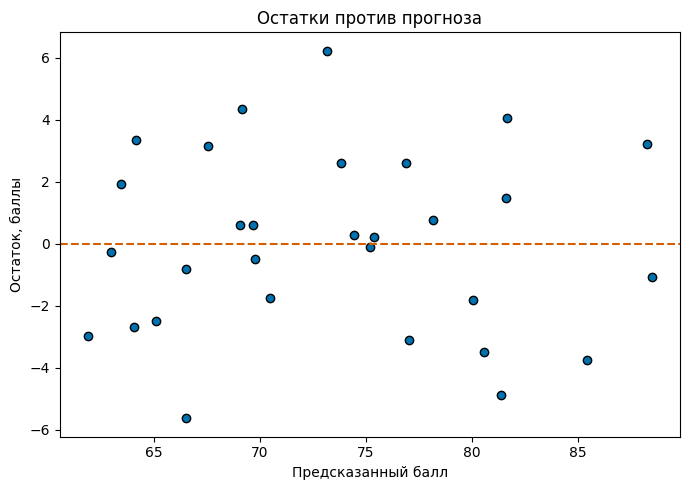

In [27]:
# Проверяем, нет ли изгиба или изменения разброса ошибок при росте прогноза.
residuals = score_model.resid
fitted = score_model.fittedvalues

plt.figure(figsize=(7, 5))
plt.scatter(fitted, residuals, color="#0072B2", edgecolors="black")
plt.axhline(0, color="#D55E00", linestyle="--")
plt.xlabel("Предсказанный балл")
plt.ylabel("Остаток, баллы")
plt.title("Остатки против прогноза")
plt.tight_layout()
plt.show()

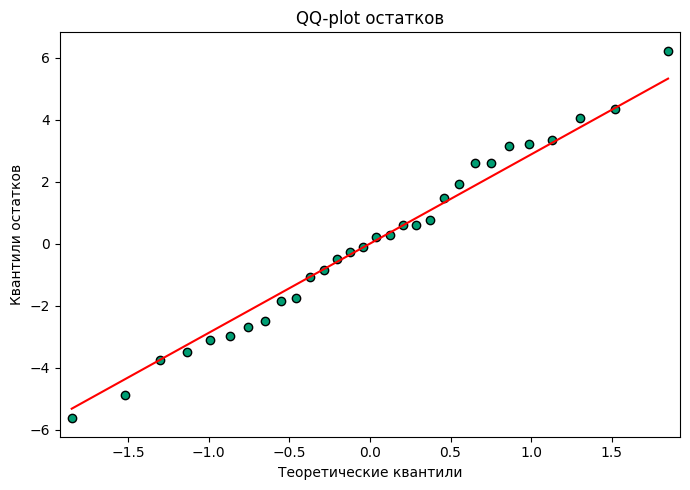

In [28]:
# Проверяем, насколько распределение остатков близко к нормальному.
fig, ax = plt.subplots(figsize=(7, 5))
sm.qqplot(
    residuals,
    line="s",
    ax=ax,
    markerfacecolor="#009E73",
    markeredgecolor="black",
)
ax.set_xlabel("Теоретические квантили")
ax.set_ylabel("Квантили остатков")
ax.set_title("QQ-plot остатков")
plt.tight_layout()
plt.show()

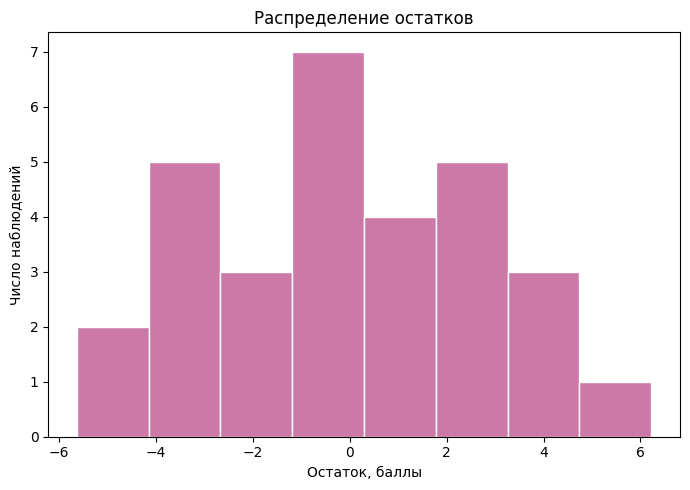

In [29]:
# Смотрим на форму распределения остатков и их симметрию.
plt.figure(figsize=(7, 5))
plt.hist(residuals, bins=8, color="#CC79A7", edgecolor="white")
plt.xlabel("Остаток, баллы")
plt.ylabel("Число наблюдений")
plt.title("Распределение остатков")
plt.tight_layout()
plt.show()

**Вывод:**

- **Остатки против прогнозов:** точки находятся по обе стороны от нуля,  
  явного изгиба или расширения разброса не видно.
- **QQ-plot:** точки в основном идут вдоль прямой,  
  поэтому распределение остатков выглядит близким к нормальному.
- **Гистограмма:** остатки примерно симметричны относительно нуля.

По графикам явных проблем с линейной формой модели и постоянством разброса ошибок не видно,  
предположение о нормальности выглядит разумным.  
Независимость ошибок по этим графикам оценить нельзя —  
для этого нужно знать, как собирались данные.